# $K_d, K_p$ Constants Analysis

## ToDo
- 실제 Loss 기반 최적 $K_d, K_p$ 계산 수식 도출 및 최적값 계산
- 실제 Loss 기반 최적 $K_d, K_p$ 변화 양상 파악
- PAPE 기반 $G^h, G$ 계산
- PAPE 기반 $G^h, G$과 실제 Loss 기반 $G^h, G$ 차이 모델링
- PAPE 값 보정 방안 도출

### $K_d, K_p$ 계산 수식 도출
- RCCDA가 제안하는 이상적인 G값의 계산은 $t_{-1}$시점에 학습한 모델의 $t_{1}$ 시점의 Loss와 $t_{-1}$시점에 학습한 모델의 가중치를 $t_0$ 시점에 발생한 데이터 드리프트를 보정한 $t_0$시점의 Loss 차이임
- 따라서 이상적인 $K_p, K_d$의 계산 방법은 아래와 같음
- $K_p(loss(t_0) - min(loss)) + K_d(loss(t_0) - loss(t_{-1}))= G^{hat} = G = loss_{keep} - loss_{retrain}$
- $K_p(loss(t_0) - min(loss))  = loss_{keep}$
- $K_d(loss(t_0) - loss(t_{-1})) = loss_{retrain}$

### $K_d, K_p$ 계산
- APIGraph 2015 데이터 활용

In [199]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [200]:
keep_loss = pd.read_csv('keep_monthly.csv')
retrain_loss = pd.read_csv('retrain_monthly.csv')

In [201]:
keep_loss.head()

,month,n_apps,TP,FP,FN,TN,loss,loss_per_app,accuracy,f1,recall
0,2015-01,4931,282,10,196,4443,206,0.041777,0.958223,0.732468,0.589958
1,2015-02,4954,316,19,166,4453,185,0.037344,0.962656,0.773562,0.655602
2,2015-03,4939,250,11,221,4457,232,0.046973,0.953027,0.683060,0.530786
3,2015-04,4946,308,16,159,4463,175,0.035382,0.964618,0.778761,0.659529
4,2015-05,4934,293,14,151,4476,165,0.033441,0.966559,0.780293,0.659910


In [202]:
retrain_loss.head()

,month,train_end,n_train,n_trees,n_apps,TP,FP,FN,TN,loss,loss_per_app,accuracy,f1,recall
0,2015-01,2014-12,137586,840,4931,392,10,86,4443,96,0.019469,0.980531,0.890909,0.820084
1,2015-02,2015-01,142517,1000,4954,445,10,37,4462,47,0.009487,0.990513,0.949840,0.923237
2,2015-03,2015-02,147471,1000,4939,443,6,28,4462,34,0.006884,0.993116,0.963043,0.940552
3,2015-04,2015-03,152410,983,4946,433,9,34,4470,43,0.008694,0.991306,0.952695,0.927195
4,2015-05,2015-04,157356,1000,4934,411,9,33,4481,42,0.008512,0.991488,0.951389,0.925676


In [203]:
kp_true = []
kd_true = []
for i in range(2, len(keep_loss)):
    kp = keep_loss['loss'][i] / (keep_loss['loss'][i-1] - min(keep_loss['loss'][:i-1]))
    kd = retrain_loss['loss'][i] / (keep_loss['loss'][i-1] - keep_loss['loss'][i-2])
    kp_true.append(kp)
    kd_true.append(kd)

In [204]:
keep_loss['kp_optimal'] = [0] * 2 + kp_true

In [205]:
keep_loss['kd_optimal'] = [0] * 2 + kd_true

Text(0.5, 1.0, 'Optimal K_p by month')

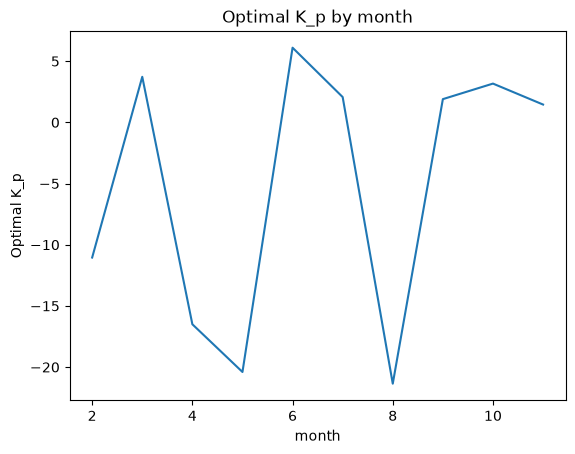

In [206]:
plt.plot([i for i in range(2, len(keep_loss))], kp_true)
plt.xlabel('month')
plt.ylabel('Optimal K_p')
plt.title('Optimal K_p by month')

Text(0.5, 1.0, 'Optimal K_d by month')

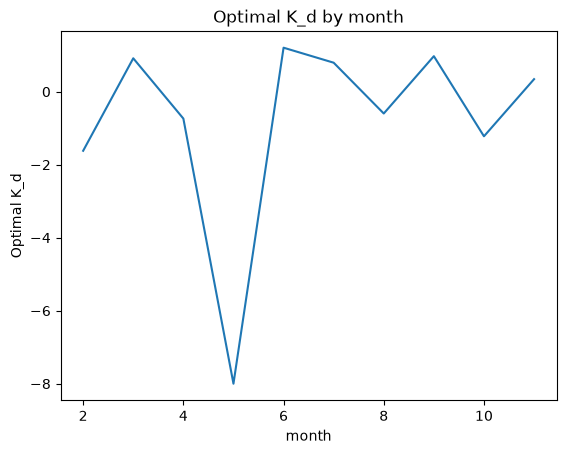

In [207]:
plt.plot([i for i in range(2, len(keep_loss))], kd_true)
plt.xlabel('month')
plt.ylabel('Optimal K_d')
plt.title('Optimal K_d by month')

## PAPE 기반 G 계산

In [208]:
pape = pd.read_csv('./pape/validation/confusion_matrix.csv')

In [209]:
uniform_pape = pape[pape['input_variant']=='all_binary__uniform'][pape['seed']==11].reset_index()
dre_pape = pape[pape['input_variant']=='all_binary__dre'][pape['seed']==11].reset_index()

/tmp/ipykernel_904311/261697815.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  uniform_pape = pape[pape['input_variant']=='all_binary__uniform'][pape['seed']==11].reset_index()
/tmp/ipykernel_904311/261697815.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  dre_pape = pape[pape['input_variant']=='all_binary__dre'][pape['seed']==11].reset_index()


In [210]:
kd_pape_uni = []
kp_pape_uni = []
for i in range(2, len(keep_loss)):
    kp = keep_loss['loss'][i] / (uniform_pape['estimated_loss'][i-1] - min(keep_loss['loss'][:i-1]))
    kd = retrain_loss['loss'][i] / (uniform_pape['estimated_loss'][i-1] - keep_loss['loss'][i-2])
    kp_pape_uni.append(kp)
    kd_pape_uni.append(kd)

In [211]:
kd_pape_dre = []
kp_pape_dre = []
for i in range(2, len(keep_loss)):
    kp = keep_loss['loss'][i] / (dre_pape['estimated_loss'][i-1] - min(keep_loss['loss'][:i-1]))
    kd = retrain_loss['loss'][i] / (dre_pape['estimated_loss'][i-1] - keep_loss['loss'][i-2])
    kp_pape_dre.append(kp)
    kd_pape_dre.append(kd)

In [212]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np

Text(0.5, 1.0, 'Optimal K_p by month')

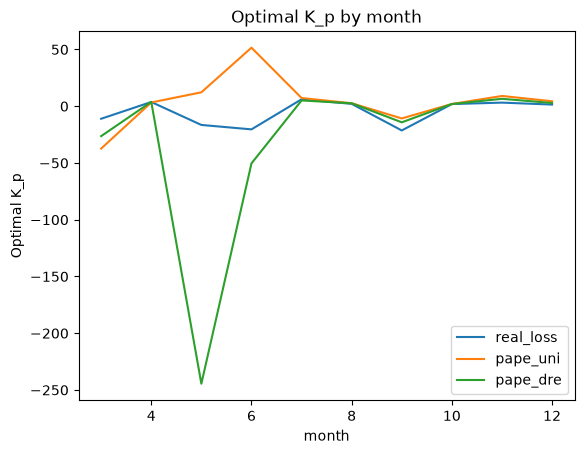

In [213]:
plt.plot([i for i in range(3, len(keep_loss)+1)], kp_true)
plt.plot([i for i in range(3, len(keep_loss)+1)], kp_pape_uni)
plt.plot([i for i in range(3, len(keep_loss)+1)], kp_pape_dre)
plt.legend(['real_loss', 'pape_uni', 'pape_dre'])
plt.xlabel('month')
plt.ylabel('Optimal K_p')
plt.title('Optimal K_p by month')

Text(0.5, 1.0, 'Optimal K_d by month')

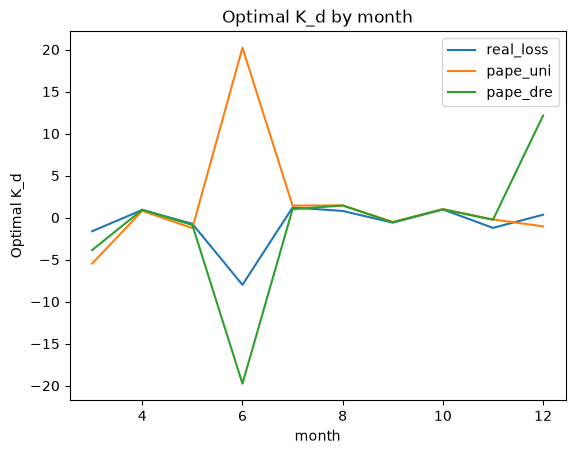

In [214]:
plt.plot([i for i in range(3, len(keep_loss)+1)], kd_true)
plt.plot([i for i in range(3, len(keep_loss)+1)], kd_pape_uni)
plt.plot([i for i in range(3, len(keep_loss)+1)], kd_pape_dre)
plt.legend(['real_loss', 'pape_uni', 'pape_dre'])
plt.xlabel('month')
plt.ylabel('Optimal K_d')
plt.title('Optimal K_d by month')

Text(0.5, 1.0, 'loss by month')

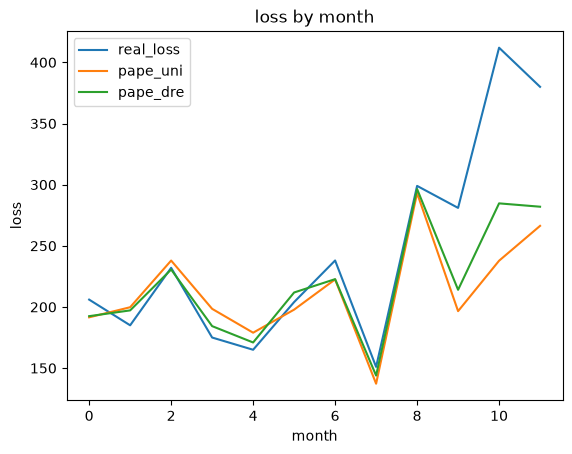

In [215]:
plt.plot([i for i in range(len(keep_loss))], keep_loss['loss'])
plt.plot([i for i in range(len(keep_loss))], uniform_pape['estimated_loss'])
plt.plot([i for i in range(len(keep_loss))], dre_pape['estimated_loss'])
plt.legend(['real_loss', 'pape_uni', 'pape_dre'])
plt.xlabel('month')
plt.ylabel('loss')
plt.title('loss by month')

Text(0.5, 1.0, 'FN by month')

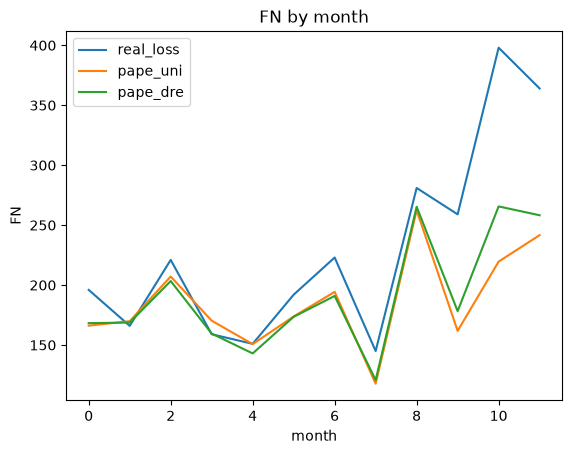

In [216]:
plt.plot([i for i in range(len(keep_loss))], keep_loss['FN'])
plt.plot([i for i in range(len(keep_loss))], uniform_pape['estimated_fn'])
plt.plot([i for i in range(len(keep_loss))], dre_pape['estimated_fn'])
plt.legend(['real_loss', 'pape_uni', 'pape_dre'])
plt.xlabel('month')
plt.ylabel('FN')
plt.title('FN by month')

Text(0.5, 1.0, 'FP by month')

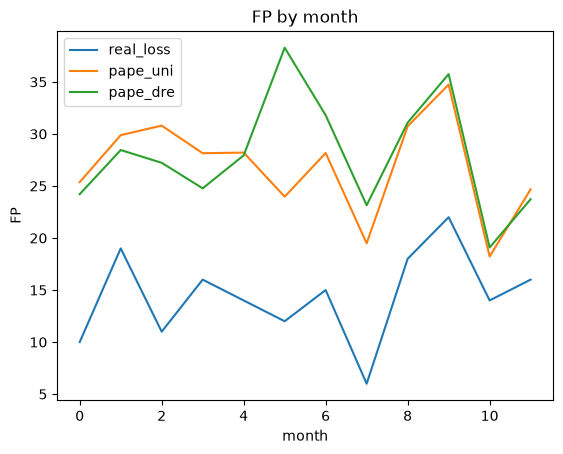

In [217]:
plt.plot([i for i in range(len(keep_loss))], keep_loss['FP'])
plt.plot([i for i in range(len(keep_loss))], uniform_pape['estimated_fp'])
plt.plot([i for i in range(len(keep_loss))], dre_pape['estimated_fp'])
plt.legend(['real_loss', 'pape_uni', 'pape_dre'])
plt.xlabel('month')
plt.ylabel('FP')
plt.title('FP by month')

Text(0.5, 1.0, 'FN diff by month')

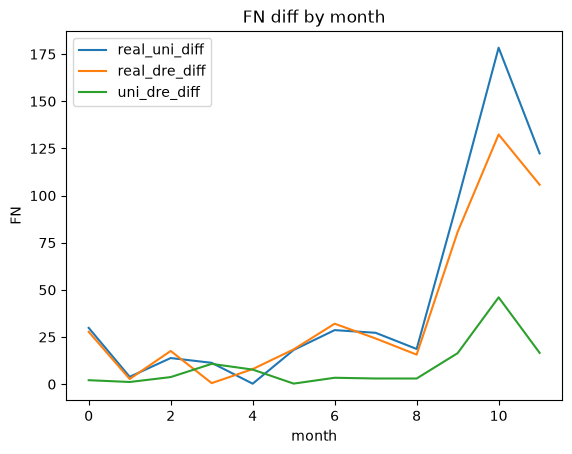

In [218]:
plt.plot([i for i in range(len(keep_loss))], list(map(abs, keep_loss['FN'] - uniform_pape['estimated_fn'])))
plt.plot([i for i in range(len(keep_loss))], list(map(abs, keep_loss['FN'] - dre_pape['estimated_fn'])))
plt.plot([i for i in range(len(keep_loss))], list(map(abs, uniform_pape['estimated_fn'] - dre_pape['estimated_fn'])))
plt.legend(['real_uni_diff', 'real_dre_diff', 'uni_dre_diff'])
plt.xlabel('month')
plt.ylabel('FN')
plt.title('FN diff by month')

Text(0.5, 1.0, 'FP diff by month')

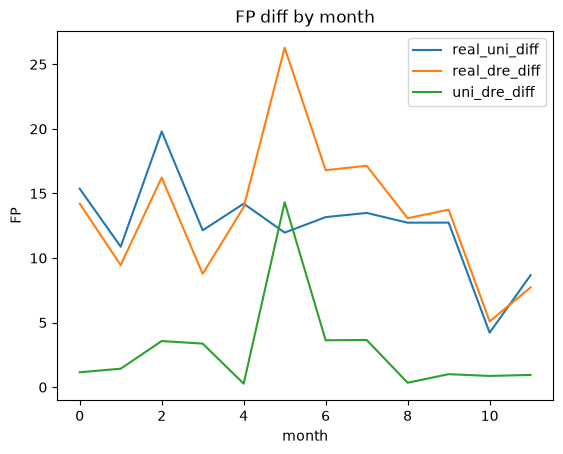

In [219]:
plt.plot([i for i in range(len(keep_loss))], list(map(abs, keep_loss['FP'] - uniform_pape['estimated_fp'])))
plt.plot([i for i in range(len(keep_loss))], list(map(abs, keep_loss['FP'] - dre_pape['estimated_fp'])))
plt.plot([i for i in range(len(keep_loss))], list(map(abs, uniform_pape['estimated_fp'] - dre_pape['estimated_fp'])))
plt.legend(['real_uni_diff', 'real_dre_diff', 'uni_dre_diff'])
plt.xlabel('month')
plt.ylabel('FP')
plt.title('FP diff by month')

Text(0.5, 1.0, 'recall by month')

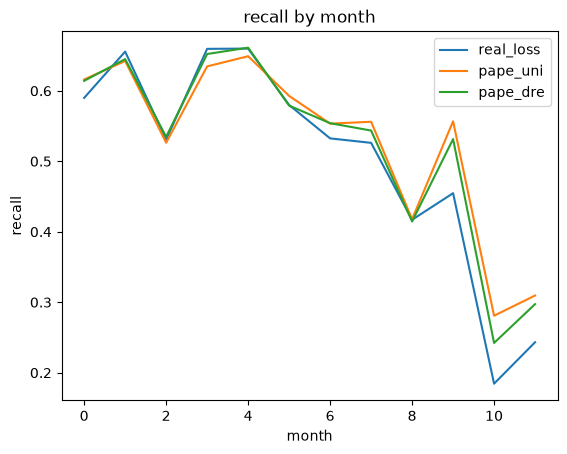

In [220]:
plt.plot([i for i in range(len(keep_loss))], keep_loss['recall'])
plt.plot([i for i in range(len(keep_loss))], uniform_pape['estimated_recall'])
plt.plot([i for i in range(len(keep_loss))], dre_pape['estimated_recall'])
plt.legend(['real_loss', 'pape_uni', 'pape_dre'])
plt.xlabel('month')
plt.ylabel('recall')
plt.title('recall by month')

In [221]:
keep_loss['kp_optimal_uni'] = [0] * 2 + kp_pape_uni
keep_loss['kp_optimal_dre'] = [0] * 2 + kp_pape_dre

In [222]:
keep_loss['kd_optimal_uni'] = [0] * 2 + kd_pape_uni
keep_loss['kd_optimal_dre'] = [0] * 2 + kd_pape_dre

In [223]:
keep_loss['FN_uni'] = uniform_pape['estimated_fn']
keep_loss['FN_dre'] = dre_pape['estimated_fn']
keep_loss['FP_uni'] = uniform_pape['estimated_fp']
keep_loss['FP_dre'] = uniform_pape['estimated_fp']

In [224]:
keep_loss

,month,n_apps,TP,FP,FN,TN,loss,loss_per_app,accuracy,f1,...,kp_optimal,kd_optimal,kp_optimal_uni,kp_optimal_dre,kd_optimal_uni,kd_optimal_dre,FN_uni,FN_dre,FP_uni,FP_dre
0,2015-01,4931,282,10,196,4443,206,0.041777,0.958223,0.732468,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,166.156131,168.260493,25.366479,25.366479
1,2015-02,4954,316,19,166,4453,185,0.037344,0.962656,0.773562,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,169.901182,168.745537,29.880353,29.880353
2,2015-03,4939,250,11,221,4457,232,0.046973,0.953027,0.683060,...,-11.047619,-1.619048,-37.308243,-26.352794,-5.467587,-3.862047,207.147788,203.390084,30.798767,30.798767
3,2015-04,4946,308,16,159,4463,175,0.035382,0.964618,0.778761,...,3.723404,0.914894,3.305220,3.836240,0.812140,0.942619,170.318351,159.552998,28.145561,28.145561
4,2015-05,4934,293,14,151,4476,165,0.033441,0.966559,0.780293,...,-16.500000,-0.736842,12.254982,-244.468985,-1.252382,-0.880966,150.749220,143.012912,28.207362,28.207362
5,2015-06,4946,265,12,192,4477,204,0.041245,0.958755,0.722071,...,-20.400000,-8.000000,51.559652,-50.393097,20.219471,-19.761999,173.843601,173.546993,23.969423,23.969423
6,2015-07,4824,254,15,223,4332,238,0.049337,0.950663,0.680965,...,6.102564,1.205128,7.253217,5.081842,1.432358,1.003557,194.341767,190.944461,28.167787,28.167787
7,2015-08,3111,161,6,145,2799,151,0.048537,0.951463,0.680761,...,2.068493,0.794118,2.625651,2.615022,1.458706,1.440514,117.760935,120.769623,19.490852,19.490852
8,2015-09,4959,201,18,281,4459,299,0.060294,0.939706,0.573466,...,-21.357143,-0.597701,-10.775469,-14.180226,-0.516138,-0.552688,262.339175,265.337995,30.738104,30.738104
9,2015-10,4963,216,22,259,4466,281,0.056619,0.943381,0.605891,...,1.898649,0.972973,1.977797,1.932329,1.013533,0.990232,161.833870,178.281232,34.741359,34.741359


In [225]:
cols = ['FP', 'FN', 'kp_optimal', 'kd_optimal']
endfix = ['', '_uni', 'dre']

In [226]:
corr_real = keep_loss[cols][2:].corr('pearson')
corr_uni = keep_loss[[i + '_uni' for i in cols]][2:].corr('pearson')
corr_dre = keep_loss[[i + '_dre' for i in cols]][2:].corr('pearson')

<Axes: >

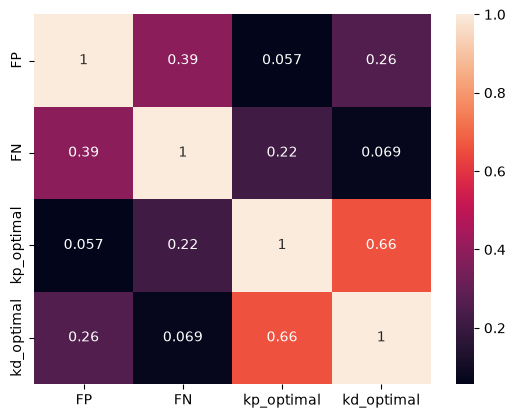

In [227]:
sns.heatmap(corr_real, annot=True)

<Axes: >

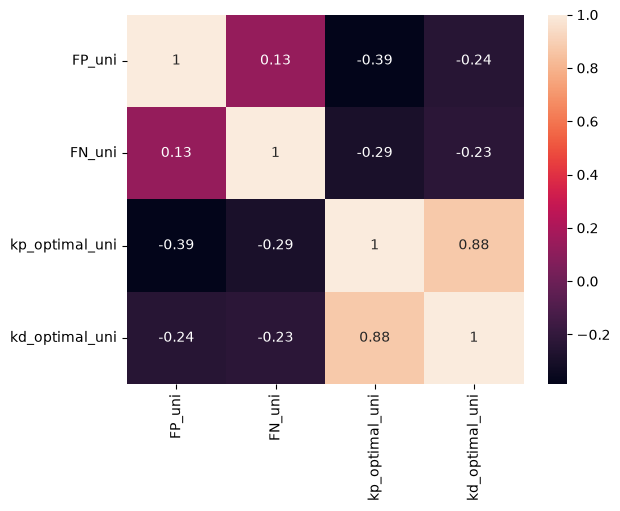

In [228]:
sns.heatmap(corr_uni, annot=True)

<Axes: >

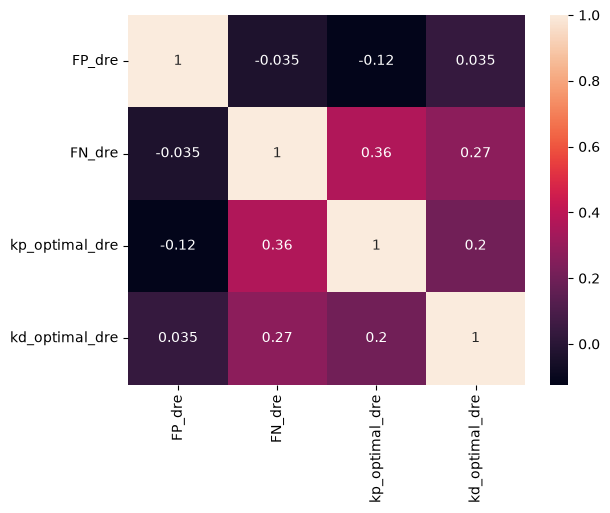

In [229]:
sns.heatmap(corr_dre, annot=True)

## $K_p, K_d$ estimation

In [261]:
tmp = keep_loss['loss'] - retrain_loss['loss']
avg_loss_diff = [sum(tmp[:i+1]) / (i + 1) for i in range(len(tmp))]

In [262]:
dre_pape['estimated_loss'][2:].values - keep_loss['loss'][1:-1].values

array([  45.61757987,  -47.67493224,   -4.0481735 ,   46.83341157,
         18.74330681,  -94.08570102,  145.42040031,  -84.97203138,
          3.70700231, -130.02914087])

Text(0.5, 1.0, 'Optimal K_p by month')

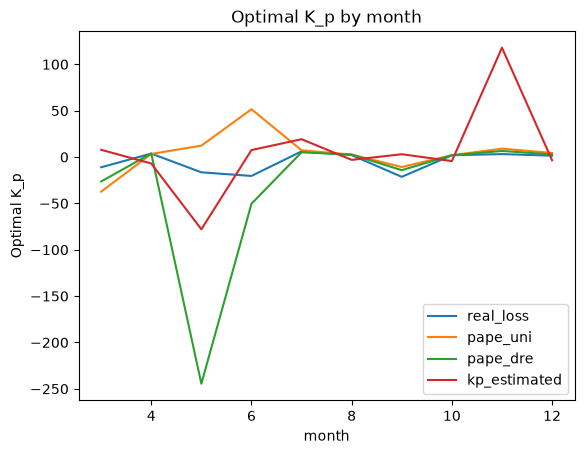

In [265]:
plt.plot([i for i in range(3, len(keep_loss)+1)], kp_true)
plt.plot([i for i in range(3, len(keep_loss)+1)], kp_pape_uni)
plt.plot([i for i in range(3, len(keep_loss)+1)], kp_pape_dre)
plt.plot([i for i in range(3, len(keep_loss)+1)], (avg_loss_diff[1:-1] + dre_pape['estimated_loss'][2:]) / (dre_pape['estimated_loss'][2:].values - keep_loss['loss'][1:-1].values))
plt.legend(['real_loss', 'pape_uni', 'pape_dre', 'kp_estimated'])
plt.xlabel('month')
plt.ylabel('Optimal K_p')
plt.title('Optimal K_p by month')

Text(0.5, 1.0, 'Optimal K_d by month')

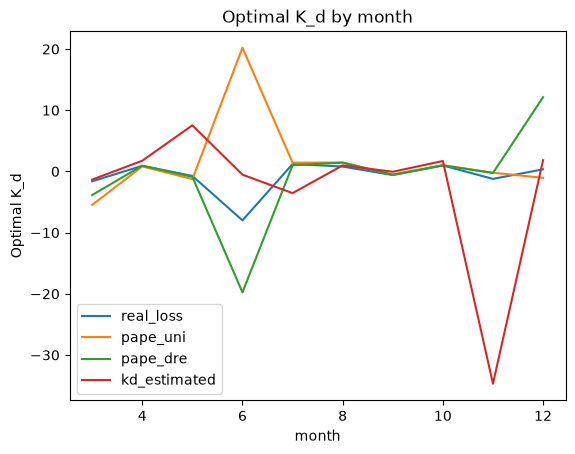

In [268]:
plt.plot([i for i in range(3, len(keep_loss)+1)], kd_true)
plt.plot([i for i in range(3, len(keep_loss)+1)], kd_pape_uni)
plt.plot([i for i in range(3, len(keep_loss)+1)], kd_pape_dre)
plt.plot([i for i in range(3, len(keep_loss)+1)], (avg_loss_diff[1:-1] - keep_loss['loss'][1:-1]) / (dre_pape['estimated_loss'][2:].values - keep_loss['loss'][1:-1].values))
plt.legend(['real_loss', 'pape_uni', 'pape_dre', 'kd_estimated'])
plt.xlabel('month')
plt.ylabel('Optimal K_d')
plt.title('Optimal K_d by month')

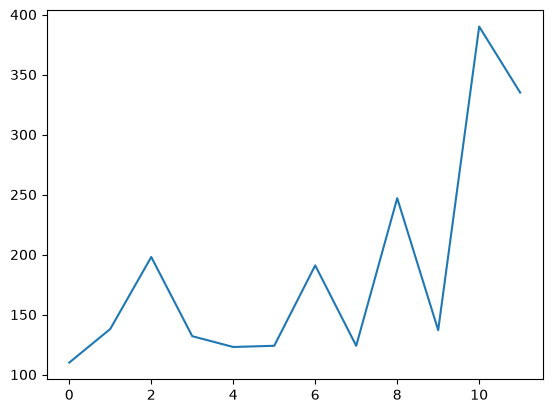

In [235]:
plt.plot([i for i in range(len(keep_loss))], tmp)

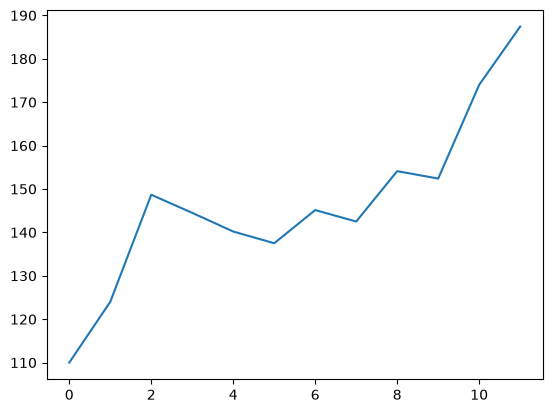

In [234]:
plt.plot([i for i in range(len(keep_loss))], avg_loss_diff)

Text(0.5, 1.0, 'loss by month')

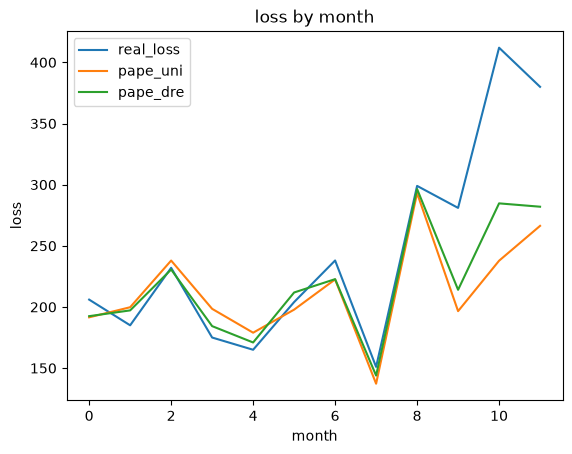

In [269]:
plt.plot([i for i in range(len(keep_loss))], keep_loss['loss'])
plt.plot([i for i in range(len(keep_loss))], uniform_pape['estimated_loss'])
plt.plot([i for i in range(len(keep_loss))], dre_pape['estimated_loss'])
plt.legend(['real_loss', 'pape_uni', 'pape_dre'])
plt.xlabel('month')
plt.ylabel('loss')
plt.title('loss by month')